# Loading Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('darkgrid')

In [2]:
df = pd.read_csv('air_quality.csv')

In [27]:
df

,timestamp,district_id,pm25,pm10,no2,o3,co,synthetic_aqi,air_quality_category,pollution_alert_flag,sensor_status
0,2023-01-01 00:00:00,D01,17.016615,30.610727,24.746377,8.975849,0.826593,42.0,Good,0,Normal
1,2023-01-01 01:00:00,D01,17.719485,26.019818,18.464261,5.547050,0.566674,44.0,Good,0,Normal
2,2023-01-01 02:00:00,D01,11.402404,20.101769,9.290825,9.566292,0.654640,28.0,Good,0,Normal
3,2023-01-01 03:00:00,D01,11.475720,23.988714,13.511296,9.697319,0.724032,28.0,Good,0,Normal
4,2023-01-01 04:00:00,D01,6.027819,19.127915,15.923252,18.149490,0.470787,19.0,Good,0,Normal
...,...,...,...,...,...,...,...,...,...,...,...
526075,2025-12-31 19:00:00,D20,14.504774,25.342128,17.660290,18.053579,0.815380,36.0,Good,0,Normal
526076,2025-12-31 20:00:00,D20,15.373394,26.528519,19.774267,17.432646,0.865917,38.0,Good,0,Normal
526077,2025-12-31 21:00:00,D20,10.557323,22.957971,15.821601,0.000000,0.695710,26.0,Good,0,Normal
526078,2025-12-31 22:00:00,D20,15.176828,31.261554,19.572849,11.045652,0.821288,37.0,Good,0,Normal


# Exploring Data

## Exploring columns and validating

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 527132 entries, 0 to 527131
Data columns (total 11 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   timestamp             527132 non-null  str    
 1   district_id           527132 non-null  str    
 2   pm25                  521691 non-null  float64
 3   pm10                  521691 non-null  float64
 4   no2                   521691 non-null  float64
 5   o3                    521691 non-null  float64
 6   co                    521691 non-null  float64
 7   synthetic_aqi         521691 non-null  float64
 8   air_quality_category  527132 non-null  str    
 9   pollution_alert_flag  527132 non-null  int64  
 10  sensor_status         527132 non-null  str    
dtypes: float64(6), int64(1), str(4)
memory usage: 61.6 MB


### Converting timestamps to datetime

In [5]:
df['timestamp'] = pd.to_datetime(df['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

### Checking for duplicated composite key (and dropping duplicates if existed)

In [6]:
# Checking for duplicated composite key
df[['timestamp', 'district_id']].duplicated().sum()

np.int64(1052)

In [7]:
df = df.drop_duplicates()

### Sorting data by districts then timestamps

In [8]:
df = df.sort_values(['district_id', 'timestamp']).reset_index(drop=True)

### Understanding columns + feature engineering (if needed)

In [9]:
df.describe()

,timestamp,pm25,pm10,no2,o3,co,synthetic_aqi,pollution_alert_flag
count,526080,520655.000000,520655.000000,520655.000000,520655.000000,520655.000000,520655.000000,526080.000000
mean,2024-07-01 23:30:00,17.260021,30.887774,22.790053,33.769902,0.834002,49.925019,0.015654
min,2023-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000,0.105382,2.000000,0.000000
25%,2023-10-01 23:45:00,9.320640,18.859158,14.708304,18.742547,0.593090,30.000000,0.000000
50%,2024-07-01 23:30:00,13.713307,25.804079,19.927828,32.208267,0.737595,43.000000,0.000000
75%,2025-04-01 23:15:00,20.825626,36.571203,27.843316,46.707479,0.973936,61.000000,0.000000
max,2025-12-31 23:00:00,119.192134,185.001350,169.678793,109.441409,6.984994,297.000000,1.000000
std,NaN,12.723678,19.319198,11.722128,19.540054,0.361380,30.220843,0.124131


In [10]:
df['air_quality_category'].unique()

<ArrowStringArray>
[                          'Good',                       'Moderate',
 'Unhealthy for Sensitive Groups',                      'Unhealthy',
                 'Very Unhealthy']
Length: 5, dtype: str

In [11]:
df['sensor_status'].unique()

<ArrowStringArray>
['Normal', 'Communication-Loss', 'Outage-Affected']
Length: 3, dtype: str

In [12]:
df['sensor_status'].value_counts()

sensor_status
Normal                520655
Communication-Loss      5323
Outage-Affected          102
Name: count, dtype: int64

In [13]:
df['pollution_alert_flag'].value_counts()

pollution_alert_flag
0    517845
1      8235
Name: count, dtype: int64

## Checking nulls

In [14]:
df.isnull().sum()

timestamp                  0
district_id                0
pm25                    5425
pm10                    5425
no2                     5425
o3                      5425
co                      5425
synthetic_aqi           5425
air_quality_category       0
pollution_alert_flag       0
sensor_status              0
dtype: int64

In [15]:
# Check if the nulls is due to abnormal sensor state
sensor_cols = ['pm25', 'pm10', 'no2','o3', 'co', 'synthetic_aqi']
for col in sensor_cols:
    print(f"{col}: {((df[col].isnull()) & (df['sensor_status'] == 'Normal')).sum()}")

# Since all the results are 0 that means There wasn't any observation where it was null while the sensor is normally working

pm25: 0
pm10: 0
no2: 0
o3: 0
co: 0
synthetic_aqi: 0


In [16]:
# Check how many missing value happened in every detection cause of (Communication-Loss)
for col in sensor_cols:
    observations = ((df[col].isnull()) & (df['sensor_status'] == 'Communication-Loss')).sum()
    print(f"{col}: {observations} which is {observations / df[col].isnull().sum() * 100:.2f}% of total null detections")
    

pm25: 5323 which is 98.12% of total null detections
pm10: 5323 which is 98.12% of total null detections
no2: 5323 which is 98.12% of total null detections
o3: 5323 which is 98.12% of total null detections
co: 5323 which is 98.12% of total null detections
synthetic_aqi: 5323 which is 98.12% of total null detections


In [17]:
# Check how many missing value happened in every detection cause of (Outage-Affected)
for col in sensor_cols:
    observations = ((df[col].isnull()) & (df['sensor_status'] == 'Outage-Affected')).sum()
    print(f"{col}: {observations} which is {observations / df[col].isnull().sum() * 100:.2f}% of total null detections")
    

pm25: 102 which is 1.88% of total null detections
pm10: 102 which is 1.88% of total null detections
no2: 102 which is 1.88% of total null detections
o3: 102 which is 1.88% of total null detections
co: 102 which is 1.88% of total null detections
synthetic_aqi: 102 which is 1.88% of total null detections


## Checking outliers

In [18]:
def find_outliers_iqr(df, column):
    Q1, Q3 = df[column].quantile(0.25), df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    return df[(df[column] < lower) | (df[column] > upper)]

for col in ['pm25', 'pm10', 'no2', 'o3', 'co', 'synthetic_aqi']:
    print(f'{col}: {len(find_outliers_iqr(df, col))}, mean: {df[col].mean():.2f}, above upper = {len(find_outliers_iqr(df, col)[df[col] > df[col].mean()])}, below lower = {len(find_outliers_iqr(df, col)[df[col] < df[col].mean()])}')

pm25: 33982, mean: 17.26, above upper = 33982, below lower = 0
pm10: 32723, mean: 30.89, above upper = 32723, below lower = 0
no2: 22436, mean: 22.79, above upper = 22436, below lower = 0
o3: 1143, mean: 33.77, above upper = 1143, below lower = 0
co: 25580, mean: 0.83, above upper = 25580, below lower = 0
synthetic_aqi: 24007, mean: 49.93, above upper = 24007, below lower = 0


## Validating Outliers

### pm25

In [19]:
pm25_outliers = find_outliers_iqr(df, 'pm25')
pm25_outliers[pm25_outliers['air_quality_category'] == 'Good']

,timestamp,district_id,pm25,pm10,no2,o3,co,synthetic_aqi,air_quality_category,pollution_alert_flag,sensor_status


### pm10

In [20]:
pm10_outliers = find_outliers_iqr(df, 'pm10')
pm10_outliers[pm10_outliers['air_quality_category'] == 'Good']

,timestamp,district_id,pm25,pm10,no2,o3,co,synthetic_aqi,air_quality_category,pollution_alert_flag,sensor_status


### no2

In [21]:
no2_outliers = find_outliers_iqr(df, 'no2')
no2_outliers

,timestamp,district_id,pm25,pm10,no2,o3,co,synthetic_aqi,air_quality_category,pollution_alert_flag,sensor_status
40,2023-01-02 16:00:00,D01,35.978882,58.305175,53.589930,39.614437,2.251327,89.0,Moderate,0,Normal
43,2023-01-02 19:00:00,D01,45.106300,74.405722,69.201618,22.443032,2.390881,112.0,Unhealthy for Sensitive Groups,0,Normal
55,2023-01-03 07:00:00,D01,55.243414,90.406154,86.003592,25.836146,3.109133,138.0,Unhealthy for Sensitive Groups,0,Normal
57,2023-01-03 09:00:00,D01,33.039873,58.948952,51.345477,44.343305,2.229736,82.0,Moderate,0,Normal
65,2023-01-03 17:00:00,D01,44.035785,75.978784,63.025481,19.796781,2.681967,110.0,Unhealthy for Sensitive Groups,0,Normal
...,...,...,...,...,...,...,...,...,...,...,...
473177,2025-12-19 17:00:00,D18,48.013780,77.529141,57.040746,28.995573,2.007554,120.0,Unhealthy for Sensitive Groups,0,Normal
473321,2025-12-25 17:00:00,D18,32.835297,48.793537,47.783636,26.637705,1.676470,82.0,Moderate,0,Normal
473417,2025-12-29 17:00:00,D18,44.153531,69.903095,49.173530,35.483072,2.039749,110.0,Unhealthy for Sensitive Groups,0,Normal
508099,2023-12-13 19:00:00,D20,39.378931,64.273465,51.778917,14.865409,2.094031,98.0,Moderate,0,Normal


### o3

In [22]:
o3_outliers = find_outliers_iqr(df, 'o3')
o3_outliers

,timestamp,district_id,pm25,pm10,no2,o3,co,synthetic_aqi,air_quality_category,pollution_alert_flag,sensor_status
2773,2023-04-26 13:00:00,D01,36.149689,58.582978,49.802103,89.438496,1.982541,90.0,Moderate,0,Normal
3444,2023-05-24 12:00:00,D01,24.263710,43.052447,33.048658,93.945349,1.573183,93.0,Moderate,0,Normal
3565,2023-05-29 13:00:00,D01,37.118794,62.245569,46.779913,95.934988,1.715007,95.0,Moderate,0,Normal
4069,2023-06-19 13:00:00,D01,17.906230,31.021389,27.151885,89.269763,0.834034,89.0,Moderate,0,Normal
4091,2023-06-20 11:00:00,D01,19.694262,35.861506,25.933125,92.894083,1.138182,92.0,Moderate,0,Normal
...,...,...,...,...,...,...,...,...,...,...,...
522037,2025-07-16 13:00:00,D20,9.747778,19.394498,16.513346,90.016519,0.667060,90.0,Moderate,0,Normal
522083,2025-07-18 11:00:00,D20,13.090840,19.750557,23.408675,91.136550,0.747441,91.0,Moderate,0,Normal
522541,2025-08-06 13:00:00,D20,8.643343,14.402143,20.685745,92.350368,0.619125,92.0,Moderate,0,Normal
522635,2025-08-10 11:00:00,D20,14.566954,27.429009,21.489375,90.451944,0.673814,90.0,Moderate,0,Normal


### co

In [23]:
co_outliers = find_outliers_iqr(df, 'co')
co_outliers_suspisiou = co_outliers[co_outliers['air_quality_category'] == 'Good']
co_outliers_suspisiou

,timestamp,district_id,pm25,pm10,no2,o3,co,synthetic_aqi,air_quality_category,pollution_alert_flag,sensor_status
82,2023-01-04 10:00:00,D01,15.711279,32.842418,29.702082,28.117066,1.780736,39.0,Good,0,Normal
83,2023-01-04 11:00:00,D01,14.991817,31.921930,24.746710,24.023698,1.562425,37.0,Good,0,Normal
108,2023-01-05 12:00:00,D01,18.699009,33.429822,34.215257,44.998941,1.769621,46.0,Good,0,Normal
116,2023-01-05 20:00:00,D01,18.361639,34.996764,27.540879,15.790643,1.670152,45.0,Good,0,Normal
138,2023-01-06 18:00:00,D01,16.414031,28.826068,29.485864,13.148221,1.986152,41.0,Good,0,Normal
...,...,...,...,...,...,...,...,...,...,...,...
498727,2025-11-18 07:00:00,D19,17.872271,34.489588,31.295444,35.772700,1.624373,44.0,Good,0,Normal
499136,2025-12-05 08:00:00,D19,18.511142,34.552904,30.590782,36.236263,1.719679,46.0,Good,0,Normal
501163,2023-02-27 19:00:00,D20,13.437103,24.284322,22.997666,18.704257,1.655565,33.0,Good,0,Normal
507810,2023-12-01 18:00:00,D20,18.113713,33.693140,20.852130,16.499577,1.600014,45.0,Good,0,Normal


### Synthetic AQI

In [24]:
aqi_outliers = find_outliers_iqr(df, 'synthetic_aqi')
aqi_outliers[aqi_outliers['air_quality_category'] == 'Moderate']

,timestamp,district_id,pm25,pm10,no2,o3,co,synthetic_aqi,air_quality_category,pollution_alert_flag,sensor_status


# Important KPIs

## Average AQI and pollution alert rate

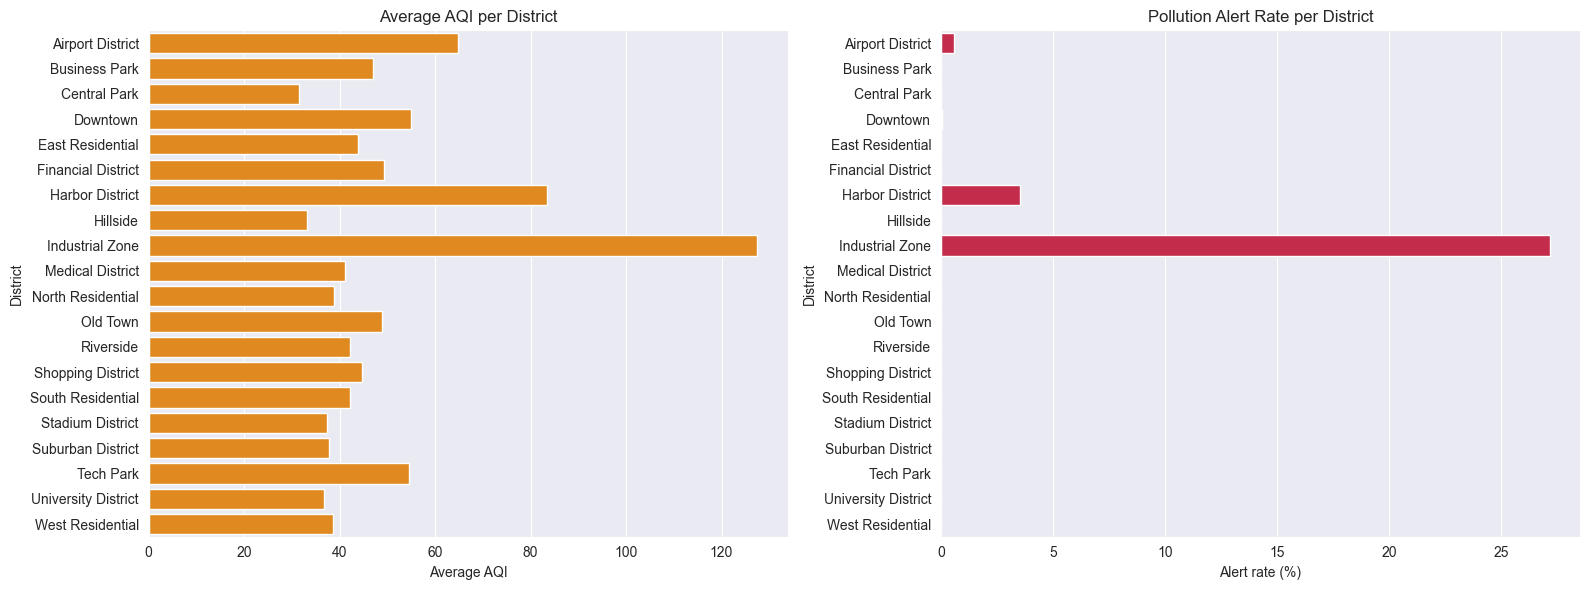

In [25]:
districts = pd.read_csv('districts.csv')
districts_air = districts.merge(df, on='district_id')

air_kpi = districts_air.groupby('district_name').agg(
    average_aqi=('synthetic_aqi', 'mean'),
    pollution_alert_rate=('pollution_alert_flag', lambda x: x.mean() * 100)
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(air_kpi, x='average_aqi', y='district_name', color='darkorange', ax=ax[0])
ax[0].set_title('Average AQI per District')
ax[0].set_xlabel('Average AQI')
ax[0].set_ylabel('District')

sns.barplot(air_kpi, x='pollution_alert_rate', y='district_name', color='crimson', ax=ax[1])
ax[1].set_title('Pollution Alert Rate per District')
ax[1].set_xlabel('Alert rate (%)')
ax[1].set_ylabel('District')

plt.tight_layout()
plt.show()

## Average PM2.5, PM10, NO2 and O3

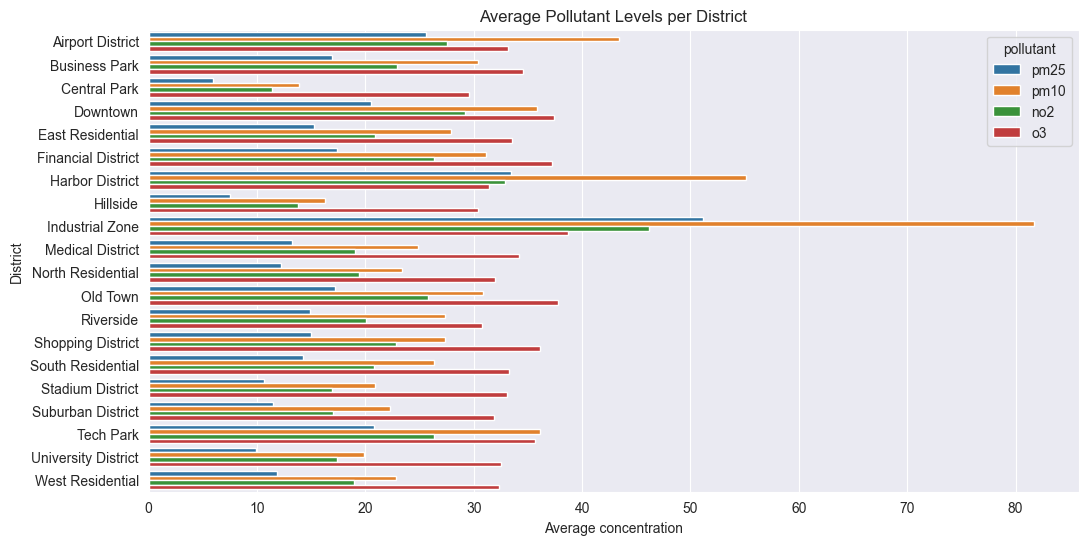

In [26]:
average_pollutants = districts_air.groupby('district_name')[['pm25', 'pm10', 'no2', 'o3']].mean().reset_index()
average_pollutants = average_pollutants.melt(id_vars='district_name', var_name='pollutant', value_name='average_value')

sns.barplot(average_pollutants, x='average_value', y='district_name', hue='pollutant')
plt.title('Average Pollutant Levels per District')
plt.xlabel('Average concentration')
plt.ylabel('District')
plt.show()

# Data Cleaning

## Handling Nulls

In [ ]:
df = df.sort_values(['district_id', 'timestamp'])
cleaned_air_quality = df.ffill().bfill()
cleaned_air_quality.to_csv('data/cleaned_air_quality.csv', index=False)